# Does Depth Pay? Machine Learning and Deep Learning for Multi-Asset Market Timing

**MScFE 690 Capstone – implementation notebook (version 3, aligned with Chapter 3 – Methodology, v3)**

### What changed in version 3 (following the guide's feedback)
1. **One primary specification**, fixed before running anything: **5-day horizon, sign label, one model pooled across the six ETFs, all five information blocks, rolling 5-year training window, long/short/flat rule, 5 bp costs.** All hypothesis tests use this specification.
2. **Pooling:** each model is trained **once on all six ETFs together** (about 6× more training rows), with **per-ETF standardisation** of features and **ETF indicator variables**, so deep models get a fair amount of data.
3. **Everything else is robustness:** 1- and 21-day horizons, separate per-ETF models, pooling of the four equity ETFs only, a threshold ("dead-zone") label, and a longer training window.

| Layer | What it does | Section |
|---|---|---|
| 1. Data | Daily prices for **SPY, QQQ, IWM, EEM, TLT, GLD** and **daily** FRED series | §1 |
| 2. Features | **34 features** in five blocks (R, T, V, X, M); the cross-asset block uses the 5-day returns of **all six** ETFs so every column means the same thing for every ETF | §3 |
| 3. Models | Benchmarks, logistic regression, random forest, XGBoost, MLP, LSTM, CNN – **pooled** across ETFs | §4–5 |
| 4. Backtest | Rolling (non-anchored) walk-forward; long / short / flat rule with $p_L$, $p_S$ chosen on validation data **for each ETF**; costs and borrowing fees on every trade | §6–7 |
| 5. Evaluation | Primary results (objectives 1–4), then the robustness experiments | §8–10 |

### The trading rule (Chapter 3, §3.8)
$$\text{position}_t = \begin{cases} +1 & \text{if } p_t > p_L \\ -1 & \text{if } p_t < p_S \\ 0 & \text{otherwise} \end{cases}$$
The thresholds are chosen on the validation period only, in four steps: (1) cost-aware limits, (2) grid search on the net Sharpe ratio, (3) stability ("plateau") rule, (4) no-edge rule.

### How to run
1. Install the requirements (next cell).
2. Choose settings in **§0 Configuration**. `RUN_SCOPE = "primary"` runs only the primary specification (fastest); `"full"` adds all robustness experiments.
3. First run: `DATA_SOURCE = "online"` (data cached in `./data/`); later: `"cache"`.
4. `FAST_MODE = True` for a quick end-to-end check. Results are **checkpointed**, so an interrupted run resumes.
5. `DATA_SOURCE = "synthetic"` is **for code testing only** – never report its results.

In [ ]:
# Requirements (run once if needed)
# !pip install numpy pandas scipy matplotlib scikit-learn xgboost yfinance tensorflow openpyxl

In [ ]:
import os, json, time, math, pickle, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, brier_score_loss)
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")


def show(df, digits=3):
    """Display a table nicely in Jupyter, or print it in a plain Python run."""
    try:
        display(df.round(digits) if hasattr(df, "round") else df)
    except NameError:
        print(df.round(digits) if hasattr(df, "round") else df)

## 0. Configuration
All research choices are here, grouped by layer. **Section A** fixes the primary specification; **Section B** lists the robustness experiments; the rest are shared settings.

In [ ]:
DATA_SOURCE = "online"   # "online" (Yahoo Finance + FRED, then cached) | "cache" (./data only) | "synthetic" (code test only)
FAST_MODE   = False      # True = quick end-to-end check with reduced settings
RUN_SCOPE   = "full"     # "primary" = primary specification only | "full" = primary + robustness experiments

CONFIG = dict(
    # ================= A. PRIMARY SPECIFICATION (fixed before any result is seen) =================
    PRIMARY = dict(
        HORIZON     = 5,            # prediction horizon h (trading days)
        LABEL       = "sign",       # "sign" = 1[return over h days > 0]
        POOLING     = "all",        # "all" = one model for the six ETFs | "separate" = one model per ETF | "equity" = 4 equity ETFs pooled
        TRAIN_YEARS = 5,            # rolling (non-anchored) training window
        ML_BLOCK_SETS = ["B1", "B2", "B3", "B4", "B5"],   # block ablation for Objective 2
        DL_BLOCK_SETS = ["B1", "B5"],
    ),
    MAIN_BLOCK_SET = "B5",          # information set used for the headline results

    # ================= B. ROBUSTNESS EXPERIMENTS (run when RUN_SCOPE = "full") =================
    # Each experiment changes ONE element of the primary specification and uses the main block set only.
    ROBUSTNESS = {
        "h1":          dict(HORIZON=1),
        "h10":         dict(HORIZON=10),
        "h21":         dict(HORIZON=21),
        "separate":    dict(POOLING="separate"),
        "equity_pool": dict(POOLING="equity"),
        "label_band":  dict(LABEL="band"),
        "train8":      dict(TRAIN_YEARS=8),
    },
    EQUITY_GROUP = ["SPY", "QQQ", "IWM", "EEM"],
    LABEL_BAND   = 0.25,            # "band" label: training rows with |h-day return| < 0.25 x typical move are dropped

    # ================= 1. DATA =================
    TICKERS      = ["SPY", "QQQ", "IWM", "EEM", "TLT", "GLD"],
    START        = "2005-01-01",
    END          = None,
    FRED_SERIES  = ["DGS10", "DTB3", "T10Y3M", "BAA10Y", "T10YIE", "VIXCLS", "DTWEXBGS"],   # daily series only
    FRED_LAG_DAYS = 1,
    DATA_DIR     = "data",
    RESULTS_DIR  = "results",

    # ================= 2. FEATURES =================
    # "ALL_RET5" expands into the 5-day returns of ALL six ETFs (same columns for every ETF -> poolable)
    FEATURES = {
        "R": ["R_ret1", "R_ret5", "R_ret21", "R_ret63", "R_mom_12_1", "R_ret21_voladj", "R_overnight"],
        "T": ["T_rsi14", "T_macd_hist", "T_px_sma50", "T_px_sma200", "T_boll_pctb20", "T_volume_z20"],
        "V": ["V_rv5", "V_rv21", "V_ewma", "V_downside21", "V_ratio_5_63", "V_parkinson21"],
        "X": ["ALL_RET5", "X_vix", "X_vix_chg5", "X_usd_ret21", "X_corr_spy_tlt63"],
        "M": ["M_term_10y3m", "M_credit_baa10y", "M_credit_chg21", "M_y10_chg21", "M_breakeven10"],
    },
    BLOCK_SETS = {"B1": ["R"], "B2": ["R", "T"], "B3": ["R", "T", "V"],
                  "B4": ["R", "T", "V", "X"], "B5": ["R", "T", "V", "X", "M"]},
    SCALE_PER_ETF = True,           # standardise each feature per ETF with training-window statistics
    ETF_INDICATORS = True,          # add ETF dummy variables when several ETFs are pooled
    CLIP_Z = 8.0,

    # ================= 3. WALK-FORWARD =================
    WALK_FORWARD = "rolling",       # "rolling" (non-anchored) | "expanding" (anchored)
    VAL_YEARS    = 2,
    TEST_START_YEAR  = 2013,
    ML_RETRAIN_YEARS = 1,
    DL_RETRAIN_YEARS = 2,
    EMBARGO_DAYS = 5,
    REFIT_ON_TRAIN_VAL = True,

    # ================= 4. MODELS =================
    BENCHMARKS = ["BUY_HOLD", "TREND_SMA200", "TSMOM_12M", "VOL_SCALED"],
    ML_MODELS  = ["LOGIT", "RF", "XGB"],
    DL_MODELS  = ["MLP", "LSTM"],
    ML_GRIDS = {
        "LOGIT": [{"C": 0.05}, {"C": 1.0}],
        "RF":    [{"max_depth": 4, "min_samples_leaf": 100}, {"max_depth": 8, "min_samples_leaf": 100}],
        "XGB":   [{"max_depth": 2, "learning_rate": 0.05}, {"max_depth": 4, "learning_rate": 0.05}],
    },
    RF_TREES = 200, XGB_TREES = 300,
    DL_GRID  = [{"units": 32, "dropout": 0.2}, {"units": 64, "dropout": 0.3}],
    SEQ_LEN  = 20, N_SEEDS = 3, DL_EPOCHS = 60, DL_PATIENCE = 8, DL_BATCH = 128, DL_LR = 1e-3,

    # ================= 5. TRADING RULE AND THRESHOLDS =================
    POSITION_MODE = "long_short",   # "long_short" | "long_flat"
    REBALANCE     = "horizon",      # "horizon" = review every h days | "daily"
    PL_GRID = (0.50, 0.70), PS_GRID = (0.30, 0.50), THRESH_STEP = 0.01,
    USE_COST_BOUNDS = True, MIN_EXPOSURE = 0.05, STABILITY_RADIUS = 1, NO_EDGE_FLAT = True,
    THRESH_OBJECTIVE = "sharpe",

    # ================= 6. COSTS =================
    COST_BPS = 5.0, BORROW_FEE = 0.005,
    COST_GRID_BPS = [0, 1, 2, 5, 10, 20, 30], BORROW_GRID = [0.0, 0.005, 0.02],
    REOPTIMISE_THRESHOLDS_IN_COST_GRID = True,
    VOL_TARGET = None, VOL_BENCH_TARGET = 0.10, ANN = 252,

    # ================= 7. EVALUATION =================
    FIXED_THRESHOLDS = [(0.50, 0.50), (0.55, 0.45), (0.60, 0.40)],
    SUBPERIODS = {"2013-2019": ("2013", "2019"), "2020-2021": ("2020", "2021"),
                  "2022": ("2022", "2022"), "2023-": ("2023", "2100")},
    BOOT_REPS = 2000, BOOT_BLOCK = 20, DSR_THRESHOLD = 0.95, RANDOM_STATE = 42,
)

if FAST_MODE:
    CONFIG["PRIMARY"].update(ML_BLOCK_SETS=["B1", "B3", "B5"], DL_BLOCK_SETS=["B5"])
    CONFIG.update(TEST_START_YEAR=2016, ML_RETRAIN_YEARS=2, DL_RETRAIN_YEARS=3, N_SEEDS=1, DL_EPOCHS=12,
                  DL_PATIENCE=3, BOOT_REPS=300, COST_GRID_BPS=[0, 5, 20],
                  ML_GRIDS={k: v[:1] for k, v in CONFIG["ML_GRIDS"].items()}, DL_GRID=CONFIG["DL_GRID"][:1],
                  ROBUSTNESS={k: CONFIG["ROBUSTNESS"][k] for k in ["h1", "separate"]})


def build_experiments():
    """List of experiments: the primary specification, then one-change-at-a-time robustness checks."""
    P = CONFIG["PRIMARY"]
    exps = {"primary": dict(P)}
    if RUN_SCOPE == "full":
        for name, change in CONFIG["ROBUSTNESS"].items():
            e = dict(P, ML_BLOCK_SETS=[CONFIG["MAIN_BLOCK_SET"]], DL_BLOCK_SETS=[CONFIG["MAIN_BLOCK_SET"]])
            e.update(change)
            exps[name] = e
    return exps


EXPERIMENTS = build_experiments()
HORIZONS = sorted({e["HORIZON"] for e in EXPERIMENTS.values()})
os.makedirs(CONFIG["DATA_DIR"], exist_ok=True)
np.random.seed(CONFIG["RANDOM_STATE"])
ANN = CONFIG["ANN"]
show(pd.DataFrame(EXPERIMENTS).T)

,HORIZON,LABEL,POOLING,TRAIN_YEARS,ML_BLOCK_SETS,DL_BLOCK_SETS
primary,5,sign,all,5,"[B1, B2, B3, B4, B5]","[B1, B5]"
h1,1,sign,all,5,[B5],[B5]
h10,10,sign,all,5,[B5],[B5]
h21,21,sign,all,5,[B5],[B5]
separate,5,sign,separate,5,[B5],[B5]
equity_pool,5,sign,equity,5,[B5],[B5]
label_band,5,band,all,5,[B5],[B5]
train8,5,sign,all,8,[B5],[B5]


## 1. Data layer
**Prices:** adjusted daily OHLCV from Yahoo Finance (Stooq as fallback). **FRED (daily series only):** 10-year yield, 3-month T-bill (also the return on cash), 10y–3m term spread, Baa–10y credit spread, 10-year breakeven inflation, VIX and the broad US dollar index. Each FRED value is used one day after its date, so it was known when the decision was made.

In [ ]:
FIELDS = ["Open", "High", "Low", "Close", "Volume"]


def _fred_csv(series_id):
    df = pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}")
    date_col = [c for c in df.columns if c.lower() in ("date", "observation_date")][0]
    s = pd.to_numeric(df[series_id], errors="coerce")
    s.index = pd.to_datetime(df[date_col])
    return s.dropna().rename(series_id)


def download_prices(tickers, start, end):
    out = {}
    try:
        import yfinance as yf
        raw = yf.download(tickers, start=start, end=end, auto_adjust=True, actions=False,
                          progress=False, group_by="column", threads=True)
        out = {f: raw[f][tickers].copy() for f in FIELDS}
        if out["Close"].dropna(how="all").empty:
            raise ValueError("empty download")
        print("Prices downloaded from Yahoo Finance.")
    except Exception as e:
        print(f"Yahoo download failed ({e}); trying Stooq ...")
        frames = {}
        for t in tickers:
            d = pd.read_csv(f"https://stooq.com/q/d/l/?s={t.lower()}.us&i=d", parse_dates=["Date"], index_col="Date")
            frames[t] = d.loc[start:end] if end else d.loc[start:]
        out = {f: pd.DataFrame({t: frames[t][f] for t in tickers}) for f in FIELDS}
    return out


def download_fred(series, start):
    out = {}
    for sid in series:
        try:
            out[sid] = _fred_csv(sid).loc[pd.Timestamp(start) - pd.DateOffset(years=2):]
        except Exception as e:
            print(f"  ! could not download {sid}: {e}")
    return out


def make_synthetic(tickers, start, end, seed=0):
    """Artificial data with the same structure as the real data. FOR CODE TESTING ONLY."""
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(start, end or "2026-06-30")
    n, k = len(dates), len(tickers)
    regime = (np.sin(np.arange(n) / 400) > 0.6).astype(float)
    vol = (0.008 + 0.012 * regime)[:, None] * rng.uniform(0.7, 1.4, k)
    base = rng.standard_normal(n)
    eps = 0.7 * base[:, None] + 0.7 * rng.standard_normal((n, k))
    eps[:, tickers.index("TLT")] = -0.4 * base + 0.9 * rng.standard_normal(n)
    mom = pd.DataFrame(eps).rolling(60, min_periods=1).mean().values * 0.05
    r = 0.0003 + vol * eps + vol * mom
    close = 100 * np.exp(np.cumsum(r, axis=0))
    open_ = close / np.exp(r) * np.exp(vol * rng.standard_normal((n, k)) * 0.3)
    high = np.maximum(open_, close) * (1 + np.abs(vol * rng.standard_normal((n, k))) * 0.5)
    low = np.minimum(open_, close) * (1 - np.abs(vol * rng.standard_normal((n, k))) * 0.5)
    volume = rng.lognormal(15, 0.3, (n, k)) * (1 + regime[:, None])
    prices = {f: pd.DataFrame(a, index=dates, columns=tickers) for f, a in zip(FIELDS, [open_, high, low, close, volume])}
    fred = {}
    for sid in CONFIG["FRED_SERIES"]:
        lvl = {"VIXCLS": 18, "DTWEXBGS": 100, "DTB3": 1.5}.get(sid, 2.0)
        fred[sid] = pd.Series(np.abs(lvl + np.cumsum(rng.normal(0, 0.03, n)) + 10 * regime * (sid == "VIXCLS")),
                              index=dates, name=sid)
    return prices, fred


def load_data():
    pfile, ffile = os.path.join(CONFIG["DATA_DIR"], "prices.csv"), os.path.join(CONFIG["DATA_DIR"], "fred_daily.csv")
    if DATA_SOURCE == "synthetic":
        print("WARNING: SYNTHETIC data - for code testing only.")
        return make_synthetic(CONFIG["TICKERS"], CONFIG["START"], CONFIG["END"])
    if DATA_SOURCE == "online":
        prices = download_prices(CONFIG["TICKERS"], CONFIG["START"], CONFIG["END"])
        fred = download_fred(CONFIG["FRED_SERIES"], CONFIG["START"])
        pd.concat({f: prices[f] for f in FIELDS}, axis=1).to_csv(pfile)
        pd.concat(fred, axis=1).to_csv(ffile)
        print(f"Cached to {pfile} and {ffile}")
        return prices, fred
    long = pd.read_csv(pfile, header=[0, 1], index_col=0, parse_dates=True)
    fr = pd.read_csv(ffile, index_col=0, parse_dates=True)
    return {f: long[f][CONFIG["TICKERS"]] for f in FIELDS}, {c: fr[c].dropna() for c in fr.columns}


prices_raw, fred_raw = load_data()
print({f: prices_raw[f].shape for f in FIELDS}, "| FRED:", sorted(fred_raw))

Prices downloaded from Yahoo Finance.
Cached to data/prices.csv and data/fred_daily.csv
{'Open': (5475, 6), 'High': (5475, 6), 'Low': (5475, 6), 'Close': (5475, 6), 'Volume': (5475, 6)} | FRED: ['BAA10Y', 'DGS10', 'DTB3', 'DTWEXBGS', 'T10Y3M', 'T10YIE', 'VIXCLS']


### 1.1 Cleaning and alignment
* Common calendar: days on which **all six ETFs** have valid prices.
* Invalid (zero, negative, missing) prices are removed, not filled.
* Each FRED series is shifted by `FRED_LAG_DAYS` and then carried forward onto the trading calendar (past values only).

In [ ]:
def clean_prices(prices):
    close = prices["Close"]
    valid = close.notna().all(axis=1) & (close > 0).all(axis=1)
    for f in ["Open", "High", "Low"]:
        valid &= (prices[f] > 0).all(axis=1)
    cal = close.index[valid]
    out = {f: prices[f].loc[cal].astype(float) for f in FIELDS}
    out["Volume"] = out["Volume"].fillna(0)
    return out, cal


def align_fred(fred, cal):
    cols = {}
    for sid, s in fred.items():
        s = s.dropna().sort_index()
        s.index = s.index + pd.Timedelta(days=CONFIG["FRED_LAG_DAYS"])
        s = s[~s.index.duplicated(keep="last")]
        cols[sid] = s.reindex(s.index.union(cal)).sort_index().ffill().reindex(cal)
    return pd.DataFrame(cols, index=cal)


prices, CAL = clean_prices(prices_raw)
macro = align_fred(fred_raw, CAL)
print(f"Trading days: {len(CAL)} ({CAL[0].date()} -> {CAL[-1].date()})")
print("First valid FRED date:\n", macro.apply(lambda s: s.first_valid_index()).to_string())

Trading days: 5475 (2005-01-03 -> 2026-10-07)
First valid FRED date:
 DGS10      2005-01-03
DTB3       2005-01-03
T10Y3M     2005-01-03
BAA10Y     2005-01-03
T10YIE     2005-01-03
VIXCLS     2005-01-03
DTWEXBGS   2006-01-03


### 1.2 Exploratory data analysis

,Ann. return,Ann. vol,Sharpe (raw),Skew,Excess kurtosis,Up-day share,Max drawdown
Ticker,,,,,,,
SPY,0.104,0.189,0.551,-0.304,14.778,0.550,-0.552
QQQ,0.143,0.216,0.664,-0.248,7.497,0.554,-0.534
IWM,0.081,0.240,0.337,-0.508,6.914,0.533,-0.586
EEM,0.071,0.276,0.257,0.022,15.529,0.526,-0.664
TLT,0.026,0.145,0.181,0.007,3.463,0.516,-0.484
GLD,0.100,0.183,0.545,-0.451,6.586,0.532,-0.456


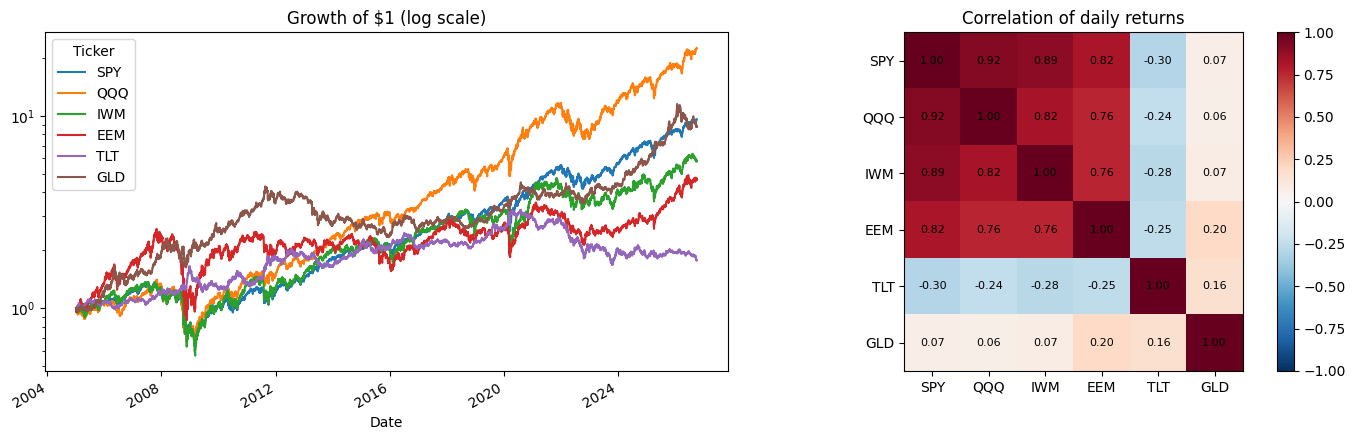

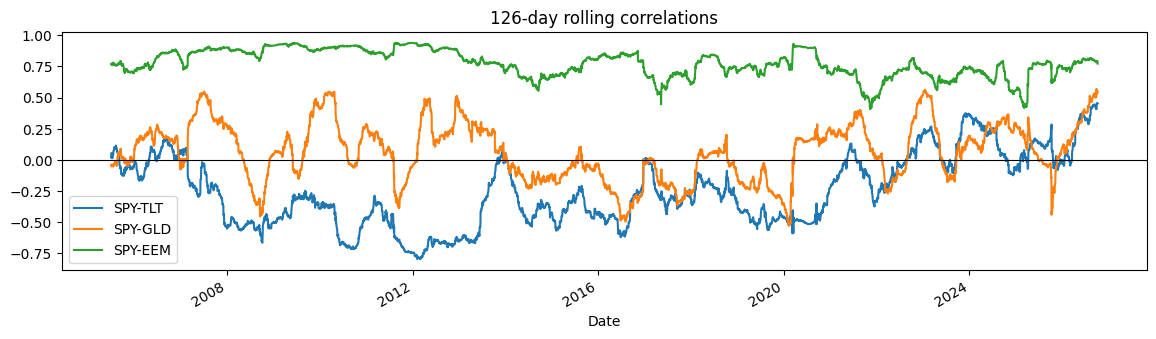

Base rate (share of positive open-to-open returns) by horizon:


,1,5,10,21
Ticker,,,,
SPY,0.551,0.601,0.631,0.673
QQQ,0.558,0.590,0.619,0.656
IWM,0.539,0.551,0.572,0.600
EEM,0.537,0.546,0.566,0.576
TLT,0.516,0.522,0.514,0.516
GLD,0.527,0.544,0.554,0.559


In [ ]:
C, O = prices["Close"], prices["Open"]
ret = np.log(C).diff()
eda = pd.DataFrame({"Ann. return": ret.mean() * ANN, "Ann. vol": ret.std() * np.sqrt(ANN),
                    "Sharpe (raw)": ret.mean() / ret.std() * np.sqrt(ANN), "Skew": ret.skew(),
                    "Excess kurtosis": ret.kurt(), "Up-day share": (ret > 0).mean(),
                    "Max drawdown": (C / C.cummax() - 1).min()})
show(eda)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(C / C.iloc[0]).plot(ax=ax[0], logy=True, title="Growth of $1 (log scale)")
cm = ret.corr()
im = ax[1].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(cm))); ax[1].set_xticklabels(cm.columns); ax[1].set_yticks(range(len(cm))); ax[1].set_yticklabels(cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax[1].text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[1].set_title("Correlation of daily returns"); plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 3.5))
for a, b in [("SPY", "TLT"), ("SPY", "GLD"), ("SPY", "EEM")]:
    ret[a].rolling(126).corr(ret[b]).plot(ax=ax, label=f"{a}-{b}")
ax.axhline(0, color="k", lw=0.8); ax.legend(); ax.set_title("126-day rolling correlations"); plt.show()

base = pd.DataFrame({h: ((O.shift(-(1 + h)) / O.shift(-1) - 1) > 0).mean() for h in HORIZONS})
print("Base rate (share of positive open-to-open returns) by horizon:"); show(base)

## 2. Target and trade timing
Decisions are made at the **close of day t** and executed at the **open of day t+1**. The return earned by the position decided at *t* is the open-to-open return
$$r_t = O_{t+2}/O_{t+1} - 1 .$$
The label for horizon *h* is $y_t^{(h)} = \mathbb{1}[\,O_{t+1+h}/O_{t+1} > 1\,]$. The typical *h*-day move $m_h$ used in the cost-aware limits (Step 1 of the threshold method) is the average absolute value of $\ln(O_{t+1+h}/O_{t+1})$ in each training window.

In [ ]:
def make_targets(O, horizons):
    r_next = O.shift(-2) / O.shift(-1) - 1
    fwd = {h: np.log(O.shift(-(1 + h)) / O.shift(-1)) for h in horizons}
    y = {h: (fwd[h] > 0).astype(float).where(fwd[h].notna()) for h in horizons}
    return r_next, fwd, y


R_NEXT, FWD, Y = make_targets(prices["Open"], HORIZONS)
RF_DAILY = (macro["DTB3"].ffill().fillna(0) / 100 / ANN).rename("rf")

## 3. Feature layer – reduced feature set (34 per ETF)
The features were chosen **before** any model was trained (Chapter 3, §3.5.1), using four rules: evidence in the literature, no near-duplicates, coverage of short, medium and long time scales, and real-time availability. The **macro block uses daily series only**. Because one model is trained on all six ETFs, every column must mean the same thing for every ETF: the cross-asset block therefore contains the 5-day returns of **all six ETFs** (for each ETF, one of these six columns is its own return).

| Block | Features (default) |
|---|---|
| R (7) | 1-, 5-, 21-, 63-day returns; 12-1 month momentum; volatility-adjusted 21-day return; overnight return |
| T (6) | RSI(14); MACD histogram / price; price vs 50-day and 200-day averages; Bollinger %B(20); volume z-score(20) |
| V (6) | realised volatility 5 and 21 days; EWMA volatility; downside volatility (21); volatility ratio 5/63; Parkinson high–low volatility (21) |
| X (10) | 5-day returns of all six ETFs; VIX level; VIX 5-day change; US dollar 21-day return; SPY–TLT 63-day correlation |
| M (5) | term spread 10y–3m; Baa–10y credit spread; 21-day change in credit spread; 21-day change in 10-year yield; 10-year breakeven inflation |

The function below computes a **library** of candidate features (including a few extra ones). Only those listed in `CONFIG["FEATURES"]` are used, so the feature set can be changed from the configuration.

In [ ]:
def rsi(c, n=14):
    d = c.diff()
    up = d.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + up / dn.replace(0, np.nan))


def zscore(s, n):
    return (s - s.rolling(n).mean()) / s.rolling(n).std()


def feature_library(tk, P, macro):
    o, h, l, c, v = (P[f][tk] for f in FIELDS)
    C = P["Close"]
    lr = np.log(c).diff()
    f = {}
    # R - returns
    f["R_ret1"] = lr
    for k in [2, 3, 5, 10, 21, 63, 126, 252]:
        f[f"R_ret{k}"] = np.log(c / c.shift(k))
    f["R_mom_12_1"] = np.log(c.shift(21) / c.shift(252))
    f["R_ret21_voladj"] = f["R_ret21"] / (lr.rolling(63).std() * np.sqrt(21))
    f["R_overnight"] = np.log(o / c.shift(1))
    f["R_intraday"] = np.log(c / o)
    # T - technical
    f["T_rsi14"] = rsi(c, 14) / 100
    f["T_rsi5"] = rsi(c, 5) / 100
    ema12, ema26 = c.ewm(span=12, adjust=False).mean(), c.ewm(span=26, adjust=False).mean()
    macd = ema12 - ema26
    f["T_macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
    for n in [20, 50, 200]:
        f[f"T_px_sma{n}"] = c / c.rolling(n).mean() - 1
    m20, s20 = c.rolling(20).mean(), c.rolling(20).std()
    f["T_boll_pctb20"] = (c - (m20 - 2 * s20)) / (4 * s20)
    f["T_volume_z20"] = zscore(np.log1p(v), 20)
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
    f["T_atr14"] = tr.rolling(14).mean() / c
    # V - volatility (own prices only)
    for n in [5, 21, 63]:
        f[f"V_rv{n}"] = lr.rolling(n).std() * np.sqrt(ANN)
    f["V_ewma"] = np.sqrt((lr ** 2).ewm(alpha=0.06, adjust=False).mean() * ANN)
    f["V_downside21"] = lr.clip(upper=0).rolling(21).std() * np.sqrt(ANN)
    f["V_ratio_5_63"] = f["V_rv5"] / f["V_rv63"]
    f["V_parkinson21"] = np.sqrt((np.log(h / l) ** 2).rolling(21).mean() / (4 * np.log(2)) * ANN)
    # X - cross-asset
    for other in C.columns:
        f[f"X_{other}_ret5"] = np.log(C[other] / C[other].shift(5))
        f[f"X_{other}_ret21"] = np.log(C[other] / C[other].shift(21))
    vix, usd = macro["VIXCLS"], macro["DTWEXBGS"]
    f["X_vix"] = vix
    f["X_vix_chg5"] = np.log(vix / vix.shift(5))
    f["X_usd_ret21"] = np.log(usd / usd.shift(21))
    allr = np.log(C).diff()
    f["X_corr_spy_tlt63"] = allr["SPY"].rolling(63).corr(allr["TLT"])
    # M - macro (daily series)
    f["M_term_10y3m"] = macro["T10Y3M"]
    f["M_credit_baa10y"] = macro["BAA10Y"]
    f["M_credit_chg21"] = macro["BAA10Y"] - macro["BAA10Y"].shift(21)
    f["M_y10_chg21"] = macro["DGS10"] - macro["DGS10"].shift(21)
    f["M_breakeven10"] = macro["T10YIE"]
    return pd.DataFrame(f).replace([np.inf, -np.inf], np.nan)


def expand(names, tk):
    out = []
    for n in names:
        if n == "ALL_RET5":
            out += [f"X_{o}_ret5" for o in CONFIG["TICKERS"]]
        elif n == "OTHER_RET5":
            out += [f"X_{o}_ret5" for o in CONFIG["TICKERS"] if o != tk]
        else:
            out.append(n)
    return out


LIB = {tk: feature_library(tk, prices, macro) for tk in CONFIG["TICKERS"]}
BLOCK_COLS = {tk: {b: expand(CONFIG["FEATURES"][b], tk) for b in CONFIG["FEATURES"]} for tk in CONFIG["TICKERS"]}
FEATS = {tk: LIB[tk][[c for b in CONFIG["FEATURES"] for c in BLOCK_COLS[tk][b]]] for tk in CONFIG["TICKERS"]}
print({b: len(c) for b, c in BLOCK_COLS["SPY"].items()}, "-> total", FEATS["SPY"].shape[1], "features per ETF")
print("First date with all features:", FEATS["SPY"].dropna().index[0].date())

# correlation check inside the selected set (near-duplicates would show |rho| > 0.9)
cc = FEATS["SPY"].dropna().corr().abs()
pairs = [(a, b, cc.loc[a, b]) for i, a in enumerate(cc.columns) for b in cc.columns[i + 1:] if cc.loc[a, b] > 0.9]
print("Feature pairs with |correlation| > 0.9 (SPY):", pairs if pairs else "none")


def cols_for(bset, tk="SPY"):
    return [c for b in CONFIG["BLOCK_SETS"][bset] for c in BLOCK_COLS[tk][b]]


def panel(group, h, bset):
    """Stacked data set for a group of ETFs: one row per (date, ETF) with a known label and all features."""
    frames = []
    for tk in group:
        valid = FEATS[tk].notna().all(axis=1) & Y[h][tk].notna()
        df = FEATS[tk].loc[valid, cols_for(bset, tk)].copy()
        df.columns = cols_for(bset, group[0])          # identical names across ETFs (ALL_RET5 design)
        df["ticker"], df["y"], df["fwd"] = tk, Y[h][tk][valid].astype(int), FWD[h][tk][valid]
        df.index.name = "date"
        frames.append(df.reset_index())
    return pd.concat(frames, ignore_index=True)


_P = panel(CONFIG["TICKERS"], CONFIG["PRIMARY"]["HORIZON"], CONFIG["MAIN_BLOCK_SET"])
print(f"Pooled primary data set: {len(_P):,} rows (date x ETF), {len(cols_for(CONFIG['MAIN_BLOCK_SET']))} features")

{'R': 7, 'T': 6, 'V': 6, 'X': 10, 'M': 5} -> total 34 features per ETF
First date with all features: 2006-02-02
Feature pairs with |correlation| > 0.9 (SPY): [('R_ret5', 'X_SPY_ret5', np.float64(1.0)), ('R_ret5', 'X_QQQ_ret5', np.float64(0.9177048535132664)), ('T_rsi14', 'T_boll_pctb20', np.float64(0.9066118315595372)), ('V_rv21', 'V_ewma', np.float64(0.9735873031620462)), ('V_rv21', 'V_downside21', np.float64(0.9628556981480675)), ('V_rv21', 'V_parkinson21', np.float64(0.970045094084684)), ('V_ewma', 'V_downside21', np.float64(0.9283534576317278)), ('V_ewma', 'V_parkinson21', np.float64(0.9577472139973601)), ('V_ewma', 'X_vix', np.float64(0.9148653809701209)), ('V_downside21', 'V_parkinson21', np.float64(0.9317890449855414)), ('V_parkinson21', 'X_vix', np.float64(0.900239049952626)), ('X_SPY_ret5', 'X_QQQ_ret5', np.float64(0.9177048535132664))]
Pooled primary data set: 31,158 rows (date x ETF), 34 features


## 4. Non-anchored (rolling) walk-forward with purging and embargo
For each test block starting in year *Y*: **training** = the `TRAIN_YEARS` years before the validation window (rolling); **validation** = the `VAL_YEARS` years before *Y* (hyperparameters, early stopping, thresholds); **test** = the block starting in *Y*. The last *h + 1 + EMBARGO_DAYS* dates before each boundary are removed (purge + embargo). Folds are defined on **dates**, so all six ETFs share exactly the same split when pooled.

In [ ]:
def make_folds(dates, h, retrain_years, train_years):
    gap = h + 1 + CONFIG["EMBARGO_DAYS"]
    yr = dates.year
    folds = []
    for y0 in range(CONFIG["TEST_START_YEAR"], yr.max() + 1, retrain_years):
        te = dates[(yr >= y0) & (yr < y0 + retrain_years)]
        va_all = dates[(yr >= y0 - CONFIG["VAL_YEARS"]) & (yr < y0)]
        tr_end = y0 - CONFIG["VAL_YEARS"]
        tr_all = dates[(yr >= tr_end - train_years) & (yr < tr_end)] if CONFIG["WALK_FORWARD"] == "rolling" else dates[yr < tr_end]
        if len(te) == 0 or len(va_all) <= gap + 50 or len(tr_all) <= gap + 250:
            continue
        folds.append(dict(year=y0, train=tr_all[:-gap], val=va_all[:-gap], test=te))
    return folds


def groups_for(pooling):
    T = CONFIG["TICKERS"]
    if pooling == "all":
        return [T]
    if pooling == "separate":
        return [[t] for t in T]
    if pooling == "equity":
        eq = [t for t in T if t in CONFIG["EQUITY_GROUP"]]
        return [eq] + [[t] for t in T if t not in eq]
    raise ValueError(pooling)


_e = EXPERIMENTS["primary"]
_dates = pd.DatetimeIndex(sorted(_P["date"].unique()))
show(pd.DataFrame([dict(test=f["year"], train=f"{f['train'][0].date()} – {f['train'][-1].date()}",
                        validation=f"{f['val'][0].date()} – {f['val'][-1].date()}",
                        train_rows_pooled=len(f["train"]) * len(CONFIG["TICKERS"]), test_days=len(f["test"]))
                   for f in make_folds(_dates, _e["HORIZON"], CONFIG["ML_RETRAIN_YEARS"], _e["TRAIN_YEARS"])]))

,test,train,validation,train_rows_pooled,test_days
0,2013,2006-02-02 – 2010-12-15,2011-01-03 – 2012-12-13,7362,252
1,2014,2007-01-03 – 2011-12-14,2012-01-03 – 2013-12-13,7494,252
2,2015,2008-01-02 – 2012-12-13,2013-01-02 – 2014-12-15,7488,252
3,2016,2009-01-02 – 2013-12-13,2014-01-02 – 2015-12-15,7482,252
4,2017,2010-01-04 – 2014-12-15,2015-01-02 – 2016-12-14,7482,251
5,2018,2011-01-03 – 2015-12-15,2016-01-04 – 2017-12-13,7482,251
6,2019,2012-01-03 – 2016-12-14,2017-01-03 – 2018-12-13,7482,252
7,2020,2013-01-02 – 2017-12-13,2018-01-02 – 2019-12-13,7488,253
8,2021,2014-01-02 – 2018-12-13,2019-01-02 – 2020-12-15,7482,252
9,2022,2015-01-02 – 2019-12-13,2020-01-02 – 2021-12-15,7482,251


## 5. Models
Every learning model receives the same number of hyperparameter configurations (`ML_GRIDS`, `DL_GRID`), chosen by validation log-loss, and is trained on the **same pooled data**. Deep models are averaged over `N_SEEDS` initialisations. The **MLP gets the same 20-day window as the LSTM and CNN, flattened** – depth without time order, the key control. When ETFs are pooled, the model also receives ETF indicator variables, so it can learn asset-specific behaviour.

In [ ]:
def make_ml(name, p, seed):
    if name == "LOGIT":
        return Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(C=p["C"], max_iter=3000))])
    if name == "RF":
        return RandomForestClassifier(n_estimators=CONFIG["RF_TREES"], max_depth=p["max_depth"],
                                      min_samples_leaf=p["min_samples_leaf"], max_features="sqrt",
                                      n_jobs=-1, random_state=seed)
    if name == "XGB":
        return xgb.XGBClassifier(n_estimators=CONFIG["XGB_TREES"], max_depth=p["max_depth"], learning_rate=p["learning_rate"],
                                 subsample=0.8, colsample_bytree=0.8, min_child_weight=20, reg_lambda=1.0,
                                 tree_method="hist", n_jobs=-1, random_state=seed, eval_metric="logloss", verbosity=0)
    raise ValueError(name)


def build_dl(name, seq_len, n_feat, units, dropout):
    from tensorflow import keras
    L2 = keras.regularizers.l2(1e-4)
    inp = keras.Input(shape=(seq_len, n_feat))
    if name == "MLP":
        x = keras.layers.Flatten()(inp)
        x = keras.layers.Dense(units, activation="relu", kernel_regularizer=L2)(x)
        x = keras.layers.Dropout(dropout)(x)
        x = keras.layers.Dense(units // 2, activation="relu", kernel_regularizer=L2)(x)
    elif name == "LSTM":
        x = keras.layers.LSTM(units, kernel_regularizer=L2)(inp)
        x = keras.layers.Dropout(dropout)(x)
        x = keras.layers.Dense(units // 2, activation="relu", kernel_regularizer=L2)(x)
    else:
        raise ValueError(name)
    model = keras.Model(inp, keras.layers.Dense(1, activation="sigmoid")(x))
    model.compile(optimizer=keras.optimizers.Adam(CONFIG["DL_LR"]), loss="binary_crossentropy")
    return model

## 6. Backtest layer – trading rule, costs and threshold selection
### 6.1 Positions and strategy returns
Positions are reviewed every *h* days (`REBALANCE="horizon"`) or every day (`"daily"`). The daily net return is
$$R_t = r^f_t + \text{pos}_t\,(r_t - r^f_t) - c\,|\Delta \text{pos}_t| - \mathbb{1}[\text{pos}_t<0]\,b/252 ,$$
where *c* is the one-way cost and *b* the annual borrowing fee. A switch from long to short is a trade of size 2.

In [ ]:
def rebalance_step(h, rebalance=None):
    return h if (rebalance or CONFIG["REBALANCE"]) == "horizon" else 1


def hold_index(n, k):
    i = np.arange(n)
    return i - (i % k)


def vol_scale(tk, index):
    if not CONFIG["VOL_TARGET"]:
        return None
    return (CONFIG["VOL_TARGET"] / LIB[tk]["V_ewma"].reindex(index)).clip(upper=1.5).fillna(1.0).values


def rule_positions(prob, pL, pS, k):
    """position = +1 if p > pL, -1 if p < pS, 0 otherwise; reviewed every k days (prob: numpy array)."""
    p = prob[hold_index(len(prob), k)]
    return np.where(p > pL, 1.0, np.where(p < pS, -1.0, 0.0))


def strategy_returns(pos, r, rf, cost_bps=None, borrow=None):
    cost_bps = CONFIG["COST_BPS"] if cost_bps is None else cost_bps
    borrow = CONFIG["BORROW_FEE"] if borrow is None else borrow
    turn = np.abs(np.diff(pos, prepend=0.0))
    fee = (pos < 0) * borrow / ANN
    gross_ex = pos * (r - rf) - fee                   # before trading costs
    net_ex = gross_ex - turn * cost_bps / 1e4
    return dict(pos=pos, turn=turn, gross_ex=gross_ex, net_ex=net_ex, rf=rf, net=net_ex + rf)


def sharpe(x):
    x = np.asarray(x); s = x.std()
    return 0.0 if (s == 0 or np.isnan(s)) else x.mean() / s * np.sqrt(ANN)

### 6.2 Choosing the thresholds $p_L$ and $p_S$ on the validation period (Chapter 3, §3.8.3)
1. **Cost-aware limits:** $p_L \ge 0.5 + c/m_h$ and $p_S \le 0.5 - c/m_h - b\,h/(504\,m_h)$, where $m_h$ is the typical *h*-day move in the training window.
2. **Grid search:** all pairs on the grid (step 0.01) within the limits, plus "never long" ($p_L=1$) and "never short" ($p_S=0$). Each pair is scored by the **net Sharpe ratio on the validation period**, with the same costs and rebalancing as in the test. Pairs in the market on fewer than `MIN_EXPOSURE` of days are discarded.
3. **Stability rule:** each pair's score is averaged with its neighbours (±1 grid step); the best average wins.
4. **No-edge rule:** if no pair has a positive validation net Sharpe, stay flat ($p_L=1$, $p_S=0$) for the test block.

In [ ]:
def threshold_grid(mode=None):
    mode = mode or CONFIG["POSITION_MODE"]
    st = CONFIG["THRESH_STEP"]
    pl = np.append(np.round(np.arange(CONFIG["PL_GRID"][0], CONFIG["PL_GRID"][1] + 1e-9, st), 4), 1.0)
    ps = np.insert(np.round(np.arange(CONFIG["PS_GRID"][0], CONFIG["PS_GRID"][1] + 1e-9, st), 4), 0, 0.0)
    if mode == "long_flat":
        ps = np.array([0.0])
    return pl, ps


def neighbourhood_mean(a, radius):
    A, B = a.shape
    out = np.full_like(a, np.nan)
    for i in range(A):
        for j in range(B):
            w = a[max(0, i - radius):i + radius + 1, max(0, j - radius):j + radius + 1]
            out[i, j] = np.nanmean(w) if np.isfinite(w).any() else np.nan
    return out


def choose_thresholds(prob, y, r, rf, m_h, h, cost_bps=None, borrow=None, mode=None, rebalance=None, scale=None):
    cost_bps = CONFIG["COST_BPS"] if cost_bps is None else cost_bps
    borrow = CONFIG["BORROW_FEE"] if borrow is None else borrow
    c = cost_bps / 1e4
    pl, ps = threshold_grid(mode)
    k = rebalance_step(h, rebalance)
    P = prob[hold_index(len(prob), k)]
    pos = (P[None, None, :] > pl[:, None, None]).astype(float) - (P[None, None, :] < ps[None, :, None]).astype(float)
    if scale is not None:
        pos = pos * scale[None, None, :]
    turn = np.abs(np.diff(pos, axis=2, prepend=0.0))
    ex = pos * (r - rf)[None, None, :] - turn * c - (pos < 0) * borrow / ANN
    sd = ex.std(axis=2)
    sh = np.where(sd > 0, ex.mean(axis=2) / np.where(sd > 0, sd, 1) * np.sqrt(ANN), np.nan)
    if CONFIG["THRESH_OBJECTIVE"] == "accuracy":
        active = pos != 0
        correct = ((pos > 0) & (y[None, None, :] == 1)) | ((pos < 0) & (y[None, None, :] == 0))
        sh = np.where(active.sum(2) > 0, correct.sum(2) / np.maximum(active.sum(2), 1), np.nan)
    exposure = (pos != 0).mean(axis=2)
    feasible = exposure >= CONFIG["MIN_EXPOSURE"]
    lbL = 0.5 + c / m_h
    ubS = 0.5 - c / m_h - borrow * h / (504 * m_h)
    if CONFIG["USE_COST_BOUNDS"]:                                     # Step 1
        okL = (pl >= lbL - 1e-9) | (pl == 1.0)
        okS = (ps <= ubS + 1e-9) | (ps == 0.0)
        feasible &= okL[:, None] & okS[None, :]
    score = np.where(feasible, sh, np.nan)                            # Step 2
    smooth = np.where(feasible, neighbourhood_mean(score, CONFIG["STABILITY_RADIUS"]), np.nan)   # Step 3
    out = dict(lbL=lbL, ubS=ubS, n_pairs=int(len(pl) * len(ps)), n_feasible=int(feasible.sum()), m_h=m_h)
    valid_best = np.isfinite(score) & (score > 0) if CONFIG["THRESH_OBJECTIVE"] == "sharpe" else np.isfinite(score)
    if not valid_best.any():                                          # Step 4
        if CONFIG["NO_EDGE_FLAT"]:
            return dict(out, pL=1.0, pS=0.0, val_score=np.nan, val_smooth=np.nan, flat=True)
        valid_best = np.isfinite(score)
        if not valid_best.any():
            return dict(out, pL=1.0, pS=0.0, val_score=np.nan, val_smooth=np.nan, flat=True)
    cand = np.where(valid_best, smooth, np.nan)
    i, j = np.unravel_index(np.nanargmax(cand), cand.shape)
    return dict(out, pL=float(pl[i]), pS=float(ps[j]), val_score=float(score[i, j]), val_smooth=float(smooth[i, j]), flat=False)

### 6.3 Pooled walk-forward runners
For each experiment, model, block set and ETF group:
1. Features are standardised **per ETF** with that ETF's training-window mean and standard deviation; ETF indicator variables are added when several ETFs are pooled.
2. With the `"band"` label (robustness only), training rows whose *h*-day return is smaller than `LABEL_BAND` × the ETF's typical move are dropped (small moves are mostly noise). Validation and test rows are never dropped.
3. The model is trained once on the pooled training rows; hyperparameters are chosen on the pooled validation rows.
4. **Thresholds $p_L$, $p_S$ are chosen separately for each ETF** from that ETF's validation probabilities, because typical moves and calibration differ across assets.

Each run is checkpointed; validation probabilities are stored so thresholds can be re-selected for other cost or trading settings without retraining.

In [ ]:
RUN_ID = hashlib.md5((json.dumps(CONFIG, sort_keys=True, default=str) + DATA_SOURCE).encode()).hexdigest()[:10]
PRED_DIR = os.path.join(CONFIG["RESULTS_DIR"], "preds", RUN_ID)
os.makedirs(PRED_DIR, exist_ok=True)
print("Run id:", RUN_ID, "->", PRED_DIR)


def _path(key):
    return os.path.join(PRED_DIR, "__".join(map(str, key)) + ".pkl")


def _load(key):
    p = _path(key)
    if os.path.exists(p):
        with open(p, "rb") as fh:
            return pickle.load(fh)
    return None


def _save(key, obj):
    with open(_path(key), "wb") as fh:
        pickle.dump(obj, fh)


def fold_thresholds(tk, h, val_df, m_h, **kw):
    idx = val_df.index
    return choose_thresholds(val_df["prob"].values, val_df["y"].values, R_NEXT[tk].reindex(idx).fillna(0).values,
                             RF_DAILY.reindex(idx).fillna(0).values, m_h, h, scale=vol_scale(tk, idx), **kw)


def scale_frame(P, cols, fit_mask):
    """Per-ETF standardisation with statistics from the rows in fit_mask; ETF indicators when pooled."""
    X = P[cols].astype(float).copy()
    keys = P["ticker"] if CONFIG["SCALE_PER_ETF"] else pd.Series("ALL", index=P.index)
    for k in keys.unique():
        rows = (keys == k).values
        fm = rows & fit_mask
        mu, sd = X.loc[fm].mean(), X.loc[fm].std().replace(0, 1).fillna(1)
        X.loc[rows] = ((X.loc[rows] - mu) / sd).clip(-CONFIG["CLIP_Z"], CONFIG["CLIP_Z"])
    if CONFIG["ETF_INDICATORS"] and P["ticker"].nunique() > 1:
        for t in sorted(P["ticker"].unique()):
            X[f"ID_{t}"] = (P["ticker"] == t).astype(float)
    return X


def typical_moves(P, mask, group):
    return {tk: float(np.mean(np.abs(P.loc[mask & (P["ticker"] == tk).values, "fwd"]))) for tk in group}


def label_mask(P, mask, mh, label):
    if label == "sign":
        return mask
    thr = P["ticker"].map(mh).values * CONFIG["LABEL_BAND"]
    return mask & (np.abs(P["fwd"].values) >= thr)


def _flatten(exp, name, group, bset, h, out, spec, attrib):
    res = {}
    for tk in group:
        pred = pd.concat(out[tk]["rows"]).sort_index()
        pred["y"] = Y[h][tk].reindex(pred.index)
        res[tk] = dict(pred=pred, val=out[tk]["vals"], folds=out[tk]["folds"], spec=[], attrib=[])
    first = group[0]
    res[first]["spec"], res[first]["attrib"] = spec, attrib     # stored once per group
    return res


def block_attribution(model, X, y, bset, cols, seed=0):
    if y.nunique() < 2:
        return []
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    out = []
    for b in CONFIG["BLOCK_SETS"][bset]:
        bc = [c for c in BLOCK_COLS[CONFIG["TICKERS"][0]][b] if c in X.columns]
        Xp = X.copy(); Xp[bc] = Xp[bc].values[rng.permutation(len(Xp))]
        out.append(dict(block=b, auc_drop=base - roc_auc_score(y, model.predict_proba(Xp)[:, 1])))
    return out


def run_ml_group(exp, name, group, bset, seed=None):
    key = (exp, name, "+".join(group), bset)
    if (cached := _load(key)) is not None:
        return cached
    e = EXPERIMENTS[exp]; h = e["HORIZON"]
    seed = CONFIG["RANDOM_STATE"] if seed is None else seed
    P = panel(group, h, bset); cols = cols_for(bset, group[0])
    dates = pd.DatetimeIndex(sorted(P["date"].unique()))
    out = {tk: dict(rows=[], vals=[], folds=[]) for tk in group}
    spec, attrib = [], []
    for f in make_folds(dates, h, CONFIG["ML_RETRAIN_YEARS"], e["TRAIN_YEARS"]):
        tr, va, te = (P["date"].isin(f[k]).values for k in ("train", "val", "test"))
        mh = typical_moves(P, tr, group)
        X = scale_frame(P, cols, tr)
        trl = label_mask(P, tr, mh, e["LABEL"])
        best = None
        for p in CONFIG["ML_GRIDS"][name]:
            m = make_ml(name, p, seed).fit(X[trl], P["y"][trl])
            pv = m.predict_proba(X[va])[:, 1]
            ll = log_loss(P["y"][va], pv, labels=[0, 1])
            spec.append(dict(experiment=exp, model=name, group="+".join(group), h=h, bset=bset, fold=f["year"],
                             params=json.dumps(p), val_logloss=ll))
            if best is None or ll < best[0]:
                best = (ll, p, pv, m)
        vt = P.loc[va, "ticker"].values
        for tk in group:
            vm = va & (P["ticker"] == tk).values
            vdf = pd.DataFrame({"prob": best[2][vt == tk], "y": P.loc[vm, "y"].values, "fold": f["year"]},
                               index=pd.DatetimeIndex(P.loc[vm, "date"].values))
            th = fold_thresholds(tk, h, vdf, mh[tk])
            out[tk]["vals"].append(vdf)
            out[tk]["folds"].append(dict(fold=f["year"], params=json.dumps(best[1]), **th))
        if CONFIG["REFIT_ON_TRAIN_VAL"]:
            trv = tr | va
            X2 = scale_frame(P, cols, trv)
            m = make_ml(name, best[1], seed).fit(X2[label_mask(P, trv, mh, e["LABEL"])], P["y"][label_mask(P, trv, mh, e["LABEL"])])
        else:
            X2, m = X, best[3]
        pt = m.predict_proba(X2[te])[:, 1]
        tt = P.loc[te, "ticker"].values
        for tk in group:
            tm = te & (P["ticker"] == tk).values
            out[tk]["rows"].append(pd.DataFrame({"prob": pt[tt == tk], "fold": f["year"]},
                                                index=pd.DatetimeIndex(P.loc[tm, "date"].values)))
        if name == "XGB" and bset == CONFIG["MAIN_BLOCK_SET"] and exp == "primary":
            attrib += [dict(fold=f["year"], **d) for d in block_attribution(m, X2[te], P["y"][te], bset, cols, seed)]
    res = _flatten(exp, name, group, bset, h, out, spec, attrib)
    _save(key, res)
    return res


def run_dl_group(exp, name, group, bset, seed=None):
    key = (exp, name, "+".join(group), bset)
    if (cached := _load(key)) is not None:
        return cached
    import tensorflow as tf
    from tensorflow import keras
    e = EXPERIMENTS[exp]; h = e["HORIZON"]; L = CONFIG["SEQ_LEN"]
    seed = CONFIG["RANDOM_STATE"] if seed is None else seed
    P = panel(group, h, bset); cols = cols_for(bset, group[0])
    dates = pd.DatetimeIndex(sorted(P["date"].unique()))
    out = {tk: dict(rows=[], vals=[], folds=[]) for tk in group}
    spec = []
    for f in make_folds(dates, h, CONFIG["DL_RETRAIN_YEARS"], e["TRAIN_YEARS"]):
        tr, va, te = (P["date"].isin(f[k]).values for k in ("train", "val", "test"))
        mh = typical_moves(P, tr, group)
        Z = scale_frame(P, cols, tr).values.astype("float32")
        trl = label_mask(P, tr, mh, e["LABEL"])

        def windows(mask):
            """Windows of the last L days of ONE ETF (never crossing ETFs), ending on rows selected by mask."""
            Ws, rows = [], []
            for tk in group:
                idx = np.where((P["ticker"] == tk).values)[0]          # date order within the ETF
                ends = idx[L - 1:]
                sel = mask[ends]
                if sel.any():
                    win = np.lib.stride_tricks.sliding_window_view(Z[idx], (L, Z.shape[1]))[:, 0]
                    Ws.append(win[sel]); rows.append(ends[sel])
            return np.concatenate(Ws), np.concatenate(rows)

        Xtr, rtr = windows(trl); Xva, rva = windows(va); Xte, rte = windows(te)
        ytr, yva = P["y"].values[rtr].astype("float32"), P["y"].values[rva].astype("float32")
        best = None
        for p in CONFIG["DL_GRID"]:
            pv_s, pt_s = [], []
            for s in range(CONFIG["N_SEEDS"]):
                keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed + s)
                model = build_dl(name, L, Z.shape[1], p["units"], p["dropout"])
                es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["DL_PATIENCE"], restore_best_weights=True)
                model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=CONFIG["DL_EPOCHS"], batch_size=CONFIG["DL_BATCH"],
                          callbacks=[es], verbose=0, shuffle=True)
                pv_s.append(model.predict(Xva, verbose=0, batch_size=1024).ravel())
                pt_s.append(model.predict(Xte, verbose=0, batch_size=1024).ravel())
            pv, pt = np.mean(pv_s, axis=0), np.mean(pt_s, axis=0)
            ll = log_loss(yva, np.clip(pv, 1e-6, 1 - 1e-6), labels=[0, 1])
            spec.append(dict(experiment=exp, model=name, group="+".join(group), h=h, bset=bset, fold=f["year"],
                             params=json.dumps(p), val_logloss=ll))
            if best is None or ll < best[0]:
                best = (ll, p, pv, pt)
        for tk in group:
            vsel = (P["ticker"].values[rva] == tk)
            vdf = pd.DataFrame({"prob": best[2][vsel], "y": yva[vsel], "fold": f["year"]},
                               index=pd.DatetimeIndex(P["date"].values[rva][vsel]))
            th = fold_thresholds(tk, h, vdf, mh[tk])
            out[tk]["vals"].append(vdf)
            out[tk]["folds"].append(dict(fold=f["year"], params=json.dumps(best[1]), **th))
            tsel = (P["ticker"].values[rte] == tk)
            out[tk]["rows"].append(pd.DataFrame({"prob": best[3][tsel], "fold": f["year"]},
                                                index=pd.DatetimeIndex(P["date"].values[rte][tsel])))
    res = _flatten(exp, name, group, bset, h, out, spec, [])
    _save(key, res)
    return res


def run_benchmark(name, tk, h):
    valid = FEATS[tk].notna().all(axis=1) & Y[h][tk].notna()
    idx = FEATS[tk].index[valid]
    idx = idx[idx.year >= CONFIG["TEST_START_YEAR"]]
    c = prices["Close"][tk]
    if name == "BUY_HOLD":
        pos = pd.Series(1.0, index=idx)
    elif name == "TREND_SMA200":
        pos = (c > c.rolling(200).mean()).astype(float).reindex(idx)
    elif name == "TSMOM_12M":
        pos = (c / c.shift(252) > 1).astype(float).reindex(idx)
    elif name == "VOL_SCALED":
        pos = (CONFIG["VOL_BENCH_TARGET"] / LIB[tk]["V_ewma"]).clip(upper=1.0).reindex(idx)
    else:
        raise ValueError(name)
    pred = pd.DataFrame({"prob": pos.clip(0, 1), "fold": idx.year, "pos_override": pos}, index=idx)
    pred["y"] = Y[h][tk].reindex(idx)
    return dict(pred=pred, val=[], folds=[], spec=[], attrib=[])

Run id: 820caa8b75 -> results/preds/820caa8b75


## 7. Run the experiments
The **primary experiment** runs every model on every block set (B1–B5 for logistic/trees, B1 and B5 for deep models). Each **robustness experiment** changes one element of the primary specification and uses the main block set (B5). Re-running this cell skips finished work.

In [ ]:
RESULTS = {}            # key: (experiment, model, ticker, block set)
jobs = []
for exp, e in EXPERIMENTS.items():
    for tk in CONFIG["TICKERS"]:
        jobs += [("BENCH", exp, b, [tk], "-") for b in CONFIG["BENCHMARKS"]]
    for g in groups_for(e["POOLING"]):
        jobs += [("ML", exp, m, g, bs) for m in CONFIG["ML_MODELS"] for bs in e["ML_BLOCK_SETS"]]
        jobs += [("DL", exp, m, g, bs) for m in CONFIG["DL_MODELS"] for bs in e["DL_BLOCK_SETS"]]
print(f"{len(jobs)} jobs ({sum(j[0] != 'BENCH' for j in jobs)} model runs) in {len(EXPERIMENTS)} experiment(s)")
t0 = time.time()
for i, (kind, exp, m, g, bs) in enumerate(jobs, 1):
    t1 = time.time()
    h = EXPERIMENTS[exp]["HORIZON"]
    if kind == "BENCH":
        RESULTS[(exp, m, g[0], bs)] = run_benchmark(m, g[0], h)
        continue
    res = run_ml_group(exp, m, g, bs) if kind == "ML" else run_dl_group(exp, m, g, bs)
    for tk, r in res.items():
        RESULTS[(exp, m, tk, bs)] = r
    print(f"[{i}/{len(jobs)}] {exp:12s} {m:6s} {'+'.join(g):24s} {bs}  {time.time() - t1:6.1f}s  (total {(time.time() - t0) / 60:5.1f} min)")
print("Done.")

## 8. Evaluation layer
### 8.1 From stored probabilities to positions, returns and metrics
Thresholds are applied **fold by fold** (each test block uses the thresholds chosen on its own validation period). Because validation probabilities are stored, thresholds can be **re-selected** for other settings (costs, long/flat mode, daily rebalancing) without retraining any model.

In [ ]:
def family(m):
    return "Benchmark" if m in CONFIG["BENCHMARKS"] else ("ML" if m in CONFIG["ML_MODELS"] else "DL")


def fold_threshold_table(res, tk, h, **variant):
    """{fold: (pL, pS)} – base thresholds, or re-selected on validation data for a variant setting."""
    if not variant:
        return {f["fold"]: (f["pL"], f["pS"]) for f in res["folds"]}
    out = {}
    for vdf, f in zip(res["val"], res["folds"]):
        th = fold_thresholds(tk, h, vdf, f["m_h"], **variant)
        out[f["fold"]] = (th["pL"], th["pS"])
    return out


def positions(res, tk, h, thresholds=None, rebalance=None):
    pred = res["pred"]
    if "pos_override" in pred:
        return pred["pos_override"].astype(float)
    thresholds = thresholds or fold_threshold_table(res, tk, h)
    k = rebalance_step(h, rebalance)
    parts = []
    for fold, g in pred.groupby("fold", sort=True):
        pL, pS = thresholds[fold]
        parts.append(pd.Series(rule_positions(g["prob"].values, pL, pS, k), index=g.index))
    pos = pd.concat(parts).sort_index()
    sc = vol_scale(tk, pos.index)
    return pos * sc if sc is not None else pos


def backtest(pos, tk, cost_bps=None, borrow=None):
    r = R_NEXT[tk].reindex(pos.index).fillna(0.0).values
    rf = RF_DAILY.reindex(pos.index).fillna(0.0).values
    out = strategy_returns(pos.values.astype(float), r, rf, cost_bps, borrow)
    return pd.DataFrame(out, index=pos.index)


def pesaran_timmermann(y, yhat):
    y, yhat = np.asarray(y), np.asarray(yhat); n = len(y)
    p, q = y.mean(), yhat.mean()
    if n < 30 or q in (0, 1) or p in (0, 1):
        return np.nan, np.nan
    P = (y == yhat).mean(); Ps = p * q + (1 - p) * (1 - q)
    vP = Ps * (1 - Ps) / n
    vPs = ((2 * p - 1) ** 2 * q * (1 - q)) / n + ((2 * q - 1) ** 2 * p * (1 - p)) / n + 4 * p * q * (1 - p) * (1 - q) / n ** 2
    if vP - vPs <= 0:
        return np.nan, np.nan
    s = (P - Ps) / np.sqrt(vP - vPs)
    return s, 1 - stats.norm.cdf(s)


def predictive_metrics(pred, pos):
    d = pred.join(pos.rename("pos")).dropna(subset=["y"])
    y = d["y"].astype(int)
    bench = "pos_override" in d
    yhat = (d["pos"] > 0).astype(int) if bench else (d["prob"] > 0.5).astype(int)   # direction call
    out = dict(n=len(y), base_rate=y.mean(), accuracy=accuracy_score(y, yhat),
               precision=precision_score(y, yhat, zero_division=0), recall=recall_score(y, yhat, zero_division=0),
               f1=f1_score(y, yhat, zero_division=0))
    out["acc_minus_base"] = out["accuracy"] - out["base_rate"]
    out["auc"] = roc_auc_score(y, d["prob"]) if (y.nunique() > 1 and d["prob"].nunique() > 1) else np.nan
    if not bench:
        pc = np.clip(d["prob"], 1e-6, 1 - 1e-6)
        out["logloss"], out["brier"] = log_loss(y, pc, labels=[0, 1]), brier_score_loss(y, pc)
    else:
        out["logloss"] = out["brier"] = np.nan
    out["pt_stat"], out["pt_pvalue"] = pesaran_timmermann(y, yhat)
    act = d["pos"] != 0
    out["coverage"] = act.mean()                                   # share of days with a position
    out["active_hit_rate"] = (((d["pos"] > 0) & (y == 1)) | ((d["pos"] < 0) & (y == 0)))[act].mean() if act.any() else np.nan
    return out


def max_drawdown(r):
    w = (1 + pd.Series(r)).cumprod()
    return (w / w.cummax() - 1).min()


def econ_metrics(bt, bh_bt=None):
    ex, net = bt["net_ex"], bt["net"]
    yrs = len(bt) / ANN
    dn = ex[ex < 0].std() * np.sqrt(ANN)
    ann_ret = (1 + net).prod() ** (1 / yrs) - 1
    mdd = max_drawdown(net)
    mt = bt["turn"].mean()
    out = dict(ann_return=ann_ret, ann_vol=net.std() * np.sqrt(ANN), sharpe=sharpe(ex), gross_sharpe=sharpe(bt["gross_ex"]),
               sortino=ex.mean() * ANN / dn if dn > 0 else np.nan, max_drawdown=mdd,
               calmar=ann_ret / abs(mdd) if mdd < 0 else np.nan, turnover_per_year=bt["turn"].sum() / yrs,
               share_long=(bt["pos"] > 0).mean(), share_short=(bt["pos"] < 0).mean(), share_flat=(bt["pos"] == 0).mean(),
               breakeven_vs_cash_bps=bt["gross_ex"].mean() / mt * 1e4 if mt > 0 else np.inf)
    if bh_bt is not None:
        target = sharpe(bh_bt["net_ex"])
        g = lambda c: sharpe(bt["gross_ex"] - bt["turn"] * c / 1e4) - target
        if g(0) <= 0:
            out["breakeven_vs_bh_bps"] = 0.0
        elif mt == 0 or g(500) > 0:
            out["breakeven_vs_bh_bps"] = np.inf
        else:
            lo, hi = 0.0, 500.0
            for _ in range(50):
                mid = (lo + hi) / 2
                lo, hi = (mid, hi) if g(mid) > 0 else (lo, mid)
            out["breakeven_vs_bh_bps"] = (lo + hi) / 2
    return out

### 8.2 Primary specification – master results table
Sections 8.2–9.3 report the **primary experiment** (5-day horizon, sign label, pooled model). All strategies for an ETF are evaluated on the **same test dates**. Direction calls for accuracy/precision/recall use $p_t > 0.5$; `coverage` is the share of days with a position and `active_hit_rate` the share of correct calls on those days.

In [ ]:
H = EXPERIMENTS["primary"]["HORIZON"]
HP = [H]
RP = {(m, tk, H, bs): r for (exp, m, tk, bs), r in RESULTS.items() if exp == "primary"}   # primary view
common_idx = {}
for (m, tk, h, bs), res in RP.items():
    idx = res["pred"].index
    common_idx[(tk, h)] = idx if (tk, h) not in common_idx else common_idx[(tk, h)].intersection(idx)

POS, BT = {}, {}
for key, res in RP.items():
    m, tk, h, bs = key
    POS[key] = positions(res, tk, h).reindex(common_idx[(tk, h)])
    BT[key] = backtest(POS[key], tk)

FULL = DLFULL = CONFIG["MAIN_BLOCK_SET"]
is_main = lambda m, bs: bs == "-" or (family(m) == "ML" and bs == FULL) or (family(m) == "DL" and bs == DLFULL)

rows = []
for key, res in RP.items():
    m, tk, h, bs = key
    row = dict(model=m, family=family(m), ticker=tk, h=h, bset=bs)
    row.update(predictive_metrics(res["pred"].loc[common_idx[(tk, h)]], POS[key]))
    row.update(econ_metrics(BT[key], BT[("BUY_HOLD", tk, h, "-")]))
    rows.append(row)
MASTER = pd.DataFrame(rows)
os.makedirs(CONFIG["RESULTS_DIR"], exist_ok=True)
MASTER.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "primary_master_results.csv"), index=False)
MAIN = MASTER[[is_main(m, b) for m, b in zip(MASTER.model, MASTER.bset)]]
LEARN = MASTER[MASTER.family != "Benchmark"]
print(f"Test period: {min(i[0] for i in common_idx.values()).date()} -> {max(i[-1] for i in common_idx.values()).date()}")
show(MASTER.head())

### 8.3 Chosen thresholds over time
The thresholds selected on each validation period are reported so their stability can be judged. `flat` marks folds where the no-edge rule applied (no threshold pair had a positive validation net Sharpe).

In [ ]:
TH_ROWS = []
for (m, tk, h, bs), res in RP.items():
    for f in res["folds"]:
        TH_ROWS.append(dict(model=m, ticker=tk, h=h, bset=bs, fold=f["fold"], pL=f["pL"], pS=f["pS"],
                            limit_pL=f["lbL"], limit_pS=f["ubS"], m_h=f["m_h"], val_sharpe=f["val_score"], flat=f["flat"]))
THRESH = pd.DataFrame(TH_ROWS)
THRESH.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "chosen_thresholds.csv"), index=False)
show(THRESH.groupby(["h", "model"]).agg(mean_limit_pL=("limit_pL", "mean"), mean_limit_pS=("limit_pS", "mean"),
                                        share_flat_folds=("flat", "mean"),
                                        median_pL=("pL", lambda s: s[s < 1].median()),
                                        median_pS=("pS", lambda s: s[s > 0].median())))
fig, axes = plt.subplots(1, len(HP), figsize=(5 * len(HP), 3.6), squeeze=False)
for ax, h in zip(axes[0], HP):
    t = THRESH[(THRESH.h == h) & (THRESH.bset.isin([FULL, DLFULL]))]
    for m, g in t.groupby("model"):
        gg = g.groupby("fold")[["pL", "pS"]].median()
        ax.plot(gg.index, gg["pL"].where(gg["pL"] < 1), marker="o", label=f"{m} pL")
        ax.plot(gg.index, gg["pS"].where(gg["pS"] > 0), marker="x", ls="--", label=f"{m} pS")
    ax.axhline(0.5, color="k", lw=0.7); ax.set_title(f"Median chosen thresholds across ETFs, h={h}")
axes[0][-1].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()

### 8.4 Objective 1 – Directional predictability
Accuracy is compared with the **base rate**; the Pesaran–Timmermann p-value tests directional skill; the Diebold–Mariano test (Harvey–Leybourne–Newbold correction, Brier loss) compares each model with logistic regression (negative statistic = better than LOGIT).

In [ ]:
show(MAIN.pivot_table(index=["h", "model"], values=["base_rate", "accuracy", "acc_minus_base", "auc", "brier",
                                                   "pt_pvalue", "coverage", "active_hit_rate"], aggfunc="mean"))
show(MAIN[MAIN.family != "Benchmark"].pivot_table(index=["h", "model"], columns="ticker", values="auc"))


def dm_test(la, lb, h=1):
    d = np.asarray(la) - np.asarray(lb); n = len(d); db = d.mean(); lags = max(h - 1, 0)
    g = [np.sum((d[k:] - db) * (d[:n - k] - db)) / n for k in range(lags + 1)]
    var = g[0] + 2 * sum((1 - k / (lags + 1)) * g[k] for k in range(1, lags + 1))
    if var <= 0:
        return np.nan, np.nan
    stat = db / np.sqrt(var / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return stat, 2 * (1 - stats.t.cdf(abs(stat), df=n - 1))


dm_rows = []
for (m, tk, h, bs), res in RP.items():
    if family(m) == "Benchmark" or (m == "LOGIT" and bs == FULL):
        continue
    ref = RP[("LOGIT", tk, h, FULL)]["pred"].loc[common_idx[(tk, h)]].dropna(subset=["y"])
    p = res["pred"].loc[ref.index]
    s, pv = dm_test((p["prob"] - p["y"]) ** 2, (ref["prob"] - ref["y"]) ** 2, h)
    dm_rows.append(dict(model=m, bset=bs, ticker=tk, h=h, dm_stat=s, p_value=pv))
DM = pd.DataFrame(dm_rows)
DM.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "dm_vs_logit.csv"), index=False)
DM["better"] = (DM.dm_stat < 0) & (DM.p_value < 0.05); DM["worse"] = (DM.dm_stat > 0) & (DM.p_value < 0.05)
show(DM.groupby(["h", "model", "bset"]).agg(mean_stat=("dm_stat", "mean"), n_better=("better", "sum"), n_worse=("worse", "sum")))

### 8.5 Objective 2 – Incremental value of each information block
Change in mean AUC and net Sharpe ratio each time a block is added (B1 → B5), by model. Then the XGBoost block attribution: drop in test AUC when one block is shuffled, by fold.

In [ ]:
for metric in ["auc", "sharpe"]:
    tab = LEARN.pivot_table(index=["h", "model"], columns="bset", values=metric, aggfunc="mean")
    print(f"\nMean {metric.upper()} by block set"); show(tab)
    print(f"Increment in {metric.upper()} when the block is added"); show(tab.diff(axis=1))

ATTR = pd.DataFrame([a for r in RP.values() for a in r.get("attrib", [])])
if len(ATTR):
    ATTR["h"] = H
if len(ATTR):
    ATTR.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "xgb_block_attribution.csv"), index=False)
    show(ATTR.groupby(["h", "block"])["auc_drop"].agg(["mean", "std", "count"]))
    fig, axes = plt.subplots(1, len(HP), figsize=(5 * len(HP), 3.4), squeeze=False)
    for ax, h in zip(axes[0], HP):
        ATTR[ATTR.h == h].groupby(["fold", "block"])["auc_drop"].mean().unstack().plot(ax=ax, marker="o")
        ax.axhline(0, color="k", lw=0.7); ax.set_title(f"XGB: AUC drop by block, h={h}")
    plt.tight_layout(); plt.show()

### 8.6 Objectives 3 & 4 – Economic performance (net of costs and borrowing fees)

In [ ]:
econ_cols = ["ann_return", "ann_vol", "sharpe", "gross_sharpe", "sortino", "max_drawdown", "turnover_per_year",
             "share_long", "share_short", "share_flat", "breakeven_vs_cash_bps", "breakeven_vs_bh_bps"]
for h in HP:
    t = MAIN[MAIN.h == h].pivot_table(index="model", columns="ticker", values="sharpe"); t["MEAN"] = t.mean(axis=1)
    print(f"\nNet Sharpe ratio, h={h} (cost {CONFIG['COST_BPS']} bp, borrow {CONFIG['BORROW_FEE']:.1%})"); show(t, 2)
print("\nMedian across ETFs"); show(MAIN.groupby(["h", "model"])[econ_cols].median())

# equal-weight six-ETF portfolio for each strategy
PORT, prow = {}, []
for (m, h, bs) in sorted({(k[0], k[2], k[3]) for k in BT}):
    parts = [BT[(m, tk, h, bs)] for tk in CONFIG["TICKERS"] if (m, tk, h, bs) in BT]
    if len(parts) < len(CONFIG["TICKERS"]):
        continue
    idx = parts[0].index
    for p in parts[1:]:
        idx = idx.intersection(p.index)
    cols = ["pos", "turn", "gross_ex", "net_ex", "rf", "net"]
    port = sum(p.loc[idx, cols] for p in parts) / len(parts)
    port["pos"] = sum(p.loc[idx, "pos"].abs() for p in parts) / len(parts)    # average gross exposure
    PORT[(m, h, bs)] = port
for (m, h, bs), port in PORT.items():
    prow.append(dict(model=m, family=family(m), h=h, bset=bs, **econ_metrics(port, PORT[("BUY_HOLD", h, "-")])))
PORT_TAB = pd.DataFrame(prow).sort_values(["h", "sharpe"], ascending=[True, False])
PORT_TAB.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "portfolio_results.csv"), index=False)
print("\nEqual-weight six-ETF portfolio"); show(PORT_TAB[["h", "model", "bset", "ann_return", "ann_vol", "sharpe", "gross_sharpe",
                                                         "sortino", "max_drawdown", "turnover_per_year"]])

h_plot = HP[min(1, len(HP) - 1)]
fig, ax = plt.subplots(figsize=(13, 4.5))
for (m, h, bs), port in PORT.items():
    if h == h_plot and is_main(m, bs):
        ax.plot((1 + port["net"]).cumprod(), label=f"{m} {bs}", lw=2 if m == "BUY_HOLD" else 1)
ax.set_title(f"Equal-weight six-ETF portfolio, net growth of $1, h={h_plot}"); ax.legend(ncol=4, fontsize=8); plt.show()

**Sharpe-ratio difference tests** (circular block bootstrap of paired daily excess returns, in the spirit of Ledoit & Wolf, 2008).

In [ ]:
def boot_sharpe_diff(a, b, reps=None, block=None, seed=0):
    reps, block = reps or CONFIG["BOOT_REPS"], block or CONFIG["BOOT_BLOCK"]
    a, b = np.asarray(a), np.asarray(b); n = len(a)
    obs = sharpe(a) - sharpe(b)
    rng = np.random.default_rng(seed); nb = int(np.ceil(n / block)); diffs = np.empty(reps)
    for i in range(reps):
        ii = ((rng.integers(0, n, nb)[:, None] + np.arange(block)[None, :]) % n).ravel()[:n]
        diffs[i] = sharpe(a[ii]) - sharpe(b[ii])
    return obs, min(1.0, np.mean(np.abs(diffs - obs) >= abs(obs)))


sd_rows = []
for (m, tk, h, bs), bt in BT.items():
    if family(m) == "Benchmark" or not is_main(m, bs):
        continue
    for ref in ["BUY_HOLD", "LOGIT"]:
        rk = (ref, tk, h, "-" if ref == "BUY_HOLD" else FULL)
        if rk == (m, tk, h, bs):
            continue
        d, p = boot_sharpe_diff(bt["net_ex"].values, BT[rk]["net_ex"].loc[bt.index].values)
        sd_rows.append(dict(model=m, ticker=tk, h=h, vs=ref, sharpe_diff=d, p_value=p))
SD = pd.DataFrame(sd_rows)
SD.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "sharpe_difference_tests.csv"), index=False)
SD["sig_better"] = (SD.sharpe_diff > 0) & (SD.p_value < 0.05); SD["sig_worse"] = (SD.sharpe_diff < 0) & (SD.p_value < 0.05)
show(SD.groupby(["h", "vs", "model"]).agg(mean_diff=("sharpe_diff", "mean"), n_sig_better=("sig_better", "sum"), n_sig_worse=("sig_worse", "sum")))

### 8.7 Transaction costs and borrowing fees
For each cost level, the thresholds are **re-chosen on the validation data at that cost** (`REOPTIMISE_THRESHOLDS_IN_COST_GRID`), as an investor facing that cost would do. Break-even costs are reported for the base case.

In [ ]:
cg_rows = []
for (m, tk, h, bs), res in RP.items():
    if not is_main(m, bs):
        continue
    for c in CONFIG["COST_GRID_BPS"]:
        for b in CONFIG["BORROW_GRID"]:
            if family(m) != "Benchmark" and CONFIG["REOPTIMISE_THRESHOLDS_IN_COST_GRID"]:
                pos = positions(res, tk, h, thresholds=fold_threshold_table(res, tk, h, cost_bps=c, borrow=b))
            else:
                pos = positions(res, tk, h)
            bt = backtest(pos.reindex(common_idx[(tk, h)]), tk, cost_bps=c, borrow=b)
            cg_rows.append(dict(model=m, ticker=tk, h=h, cost_bps=c, borrow=b, sharpe=sharpe(bt["net_ex"]),
                                turnover=bt["turn"].sum() / (len(bt) / ANN)))
CG = pd.DataFrame(cg_rows)
CG.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "cost_grid.csv"), index=False)
fig, axes = plt.subplots(1, len(HP), figsize=(5 * len(HP), 3.8), squeeze=False)
for ax, h in zip(axes[0], HP):
    CG[(CG.h == h) & (CG.borrow == CONFIG["BORROW_FEE"])].groupby(["cost_bps", "model"])["sharpe"].mean().unstack().plot(ax=ax, marker="o")
    ax.set_title(f"Mean net Sharpe vs one-way cost, h={h}"); ax.set_xlabel("cost (bp)")
plt.tight_layout(); plt.show()
print("Mean net Sharpe by borrowing fee (base trading cost):")
show(CG[CG.cost_bps == CONFIG["COST_BPS"]].pivot_table(index=["h", "model"], columns="borrow", values="sharpe", aggfunc="mean"), 2)
print("Break-even cost versus buy-and-hold (bp per unit traded; 0 = never beats it, inf = beats it at any cost):")
show(MAIN[MAIN.family != "Benchmark"].pivot_table(index=["h", "model"], columns="ticker", values="breakeven_vs_bh_bps"), 1)

### 8.8 Selection bias – deflated Sharpe ratio
Two versions are reported: **DSR (models)** counts every model × block set × horizon × hyperparameter configuration tried per ETF; **DSR (models + thresholds)** also counts every threshold pair searched, which is the most conservative correction (Chapter 3, §3.10.4). Values above `DSR_THRESHOLD` (0.95) indicate a result that survives selection bias.

In [ ]:
SPEC = pd.DataFrame([s for r in RP.values() for s in r.get("spec", [])])
SPEC.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "specification_log.csv"), index=False)
SPEC = SPEC[SPEC.experiment == "primary"] if len(SPEC) else SPEC
_nv = SPEC[["model", "bset", "params"]].drop_duplicates().shape[0] if len(SPEC) else 1
n_models = pd.Series(_nv, index=CONFIG["TICKERS"])   # same pooled models serve every ETF
n_pairs = int(np.median([f["n_pairs"] for r in RP.values() for f in r["folds"]])) if len(THRESH) else 1
print(f"Configurations fitted: {len(SPEC)}; strategy variants per ETF: {n_models.to_dict()}; threshold pairs per search: {n_pairs}")


def deflated_sharpe(ret, n_trials, sr_var):
    ret = pd.Series(ret).dropna(); T = len(ret)
    if ret.std() == 0 or T < 30:
        return np.nan
    sr = ret.mean() / ret.std()
    sk, ku = stats.skew(ret), stats.kurtosis(ret, fisher=False)
    g, N = 0.5772156649, max(int(n_trials), 2)
    sr0 = np.sqrt(sr_var) * ((1 - g) * stats.norm.ppf(1 - 1 / N) + g * stats.norm.ppf(1 - 1 / (N * np.e)))
    return stats.norm.cdf((sr - sr0) * np.sqrt(T - 1) / np.sqrt(max(1 - sk * sr + (ku - 1) / 4 * sr ** 2, 1e-12)))


dsr_rows = []
for tk in CONFIG["TICKERS"]:
    cand = {k: bt for k, bt in BT.items() if k[1] == tk and family(k[0]) != "Benchmark"}
    srs = np.array([bt["net_ex"].mean() / bt["net_ex"].std() if bt["net_ex"].std() > 0 else np.nan for bt in cand.values()])
    var = np.nanvar(srs, ddof=1) if np.isfinite(srs).sum() > 1 else 0.0
    for k, bt in cand.items():
        dsr_rows.append(dict(model=k[0], ticker=tk, h=k[2], bset=k[3], sharpe=sharpe(bt["net_ex"]),
                             dsr_models=deflated_sharpe(bt["net_ex"], n_models.get(tk, len(cand)), var),
                             dsr_models_thresholds=deflated_sharpe(bt["net_ex"], n_models.get(tk, len(cand)) * n_pairs, var)))
DSR = pd.DataFrame(dsr_rows).sort_values("dsr_models", ascending=False)
DSR.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "deflated_sharpe.csv"), index=False)
show(DSR.head(15))
print(f"DSR > {CONFIG['DSR_THRESHOLD']}: models-only {(DSR.dsr_models > CONFIG['DSR_THRESHOLD']).sum()}, "
      f"with thresholds {(DSR.dsr_models_thresholds > CONFIG['DSR_THRESHOLD']).sum()} of {len(DSR)}")

## 9. Robustness
### 9.1 Sub-periods and VIX regimes

In [ ]:
vix = macro["VIXCLS"]
reg_rows = []
for (m, tk, h, bs), bt in BT.items():
    if not is_main(m, bs):
        continue
    ex = bt["net_ex"]
    for name, (a, b) in CONFIG["SUBPERIODS"].items():
        e = ex.loc[a:b]
        if len(e) > 60:
            reg_rows.append(dict(model=m, ticker=tk, h=h, split="period", regime=name, sharpe=sharpe(e)))
    terc = pd.qcut(vix.reindex(ex.index), 3, labels=["low VIX", "mid VIX", "high VIX"])
    for lab in terc.cat.categories:
        reg_rows.append(dict(model=m, ticker=tk, h=h, split="vix", regime=lab, sharpe=sharpe(ex[terc == lab])))
REG = pd.DataFrame(reg_rows)
REG.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "regime_results.csv"), index=False)
for split in ["period", "vix"]:
    print(f"\nMean net Sharpe by {split}")
    show(REG[REG.split == split].pivot_table(index=["h", "model"], columns="regime", values="sharpe", aggfunc="mean"), 2)

### 9.2 Threshold-method and rebalancing variants
* **Fixed thresholds** (applied ex post, for sensitivity only): pairs in `FIXED_THRESHOLDS`.
* **Long/flat:** thresholds re-chosen on validation with $p_S = 0$.
* **Daily rebalancing:** thresholds re-chosen on validation with daily position reviews.

In [ ]:
var_rows = []
for (m, tk, h, bs), res in RP.items():
    if family(m) == "Benchmark" or not is_main(m, bs):
        continue
    idx = common_idx[(tk, h)]
    variants = {"base": positions(res, tk, h)}
    for pL, pS in CONFIG["FIXED_THRESHOLDS"]:
        variants[f"fixed {pL:.2f}/{pS:.2f}"] = positions(res, tk, h, thresholds={f: (pL, pS) for f in res["pred"]["fold"].unique()})
    variants["long_flat"] = positions(res, tk, h, thresholds=fold_threshold_table(res, tk, h, mode="long_flat"))
    if h > 1:
        variants["daily_rebalance"] = positions(res, tk, h, rebalance="daily",
                                                thresholds=fold_threshold_table(res, tk, h, rebalance="daily"))
    for name, pos in variants.items():
        bt = backtest(pos.reindex(idx), tk)
        var_rows.append(dict(model=m, ticker=tk, h=h, variant=name, sharpe=sharpe(bt["net_ex"]),
                             turnover=bt["turn"].sum() / (len(bt) / ANN)))
VAR = pd.DataFrame(var_rows)
VAR.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "threshold_variants.csv"), index=False)
print("Mean net Sharpe by variant"); show(VAR.pivot_table(index=["h", "model"], columns="variant", values="sharpe", aggfunc="mean"), 2)
print("Mean turnover per year by variant"); show(VAR.pivot_table(index=["h", "model"], columns="variant", values="turnover", aggfunc="mean"), 1)

### 9.3 Per-ETF results and equity curves (primary specification)

In [ ]:
show(MAIN[MAIN.family != "Benchmark"].groupby(["model", "h"])[["auc", "acc_minus_base", "sharpe", "turnover_per_year"]].mean().unstack("h"))
n = len(CONFIG["TICKERS"])
fig, axes = plt.subplots(int(np.ceil(n / 2)), 2, figsize=(14, 3.2 * int(np.ceil(n / 2))), squeeze=False)
for ax, tk in zip(axes.ravel(), CONFIG["TICKERS"]):
    for (m, t2, h, bs), bt in BT.items():
        if t2 == tk and h == h_plot and is_main(m, bs) and m in ["BUY_HOLD", "TREND_SMA200", "VOL_SCALED", "LOGIT", "XGB", "MLP", "LSTM"]:
            ax.plot((1 + bt["net"]).cumprod(), label=m, lw=2 if m == "BUY_HOLD" else 1)
    ax.set_title(f"{tk} – net growth of $1, h={h_plot}"); ax.legend(fontsize=7, ncol=4)
plt.tight_layout(); plt.show()

### 9.4 Robustness experiments (one change at a time)
Each experiment changes **one** element of the primary specification: the horizon (1 or 21 days), separate per-ETF models instead of one pooled model, pooling of the four equity ETFs only, the "band" label, or an 8-year training window. All use the main block set and the same threshold method and costs. The question is whether the conclusions of the primary specification **change**.

In [ ]:
rob_rows = []
EXP_COMMON = {}
for (exp, m, tk, bs), res in RESULTS.items():
    idx = res["pred"].index
    EXP_COMMON[(exp, tk)] = idx if (exp, tk) not in EXP_COMMON else EXP_COMMON[(exp, tk)].intersection(idx)
EXP_BT = {}
for (exp, m, tk, bs), res in RESULTS.items():
    if not (bs == "-" or bs == CONFIG["MAIN_BLOCK_SET"]):
        continue
    h = EXPERIMENTS[exp]["HORIZON"]
    idx = EXP_COMMON[(exp, tk)]
    pos = positions(res, tk, h).reindex(idx)
    bt = backtest(pos, tk)
    EXP_BT[(exp, m, tk)] = bt
    pm = predictive_metrics(res["pred"].loc[idx], pos)
    rob_rows.append(dict(experiment=exp, model=m, family=family(m), ticker=tk, h=h, auc=pm["auc"],
                         acc_minus_base=pm["acc_minus_base"], sharpe=sharpe(bt["net_ex"]),
                         turnover=bt["turn"].sum() / (len(bt) / ANN)))
ROB = pd.DataFrame(rob_rows)
ROB.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "robustness_experiments.csv"), index=False)
order = list(EXPERIMENTS)
print("Mean test AUC across ETFs, by experiment")
show(ROB[ROB.family != "Benchmark"].pivot_table(index="model", columns="experiment", values="auc", aggfunc="mean")[order])
print("Mean net Sharpe across ETFs, by experiment")
show(ROB.pivot_table(index="model", columns="experiment", values="sharpe", aggfunc="mean")[order], 2)

# equal-weight portfolio Sharpe by experiment
pr = []
for exp in EXPERIMENTS:
    for m in sorted({k[1] for k in EXP_BT if k[0] == exp}):
        parts = [EXP_BT[(exp, m, tk)] for tk in CONFIG["TICKERS"] if (exp, m, tk) in EXP_BT]
        if len(parts) < len(CONFIG["TICKERS"]):
            continue
        idx = parts[0].index
        for p in parts[1:]:
            idx = idx.intersection(p.index)
        pr.append(dict(experiment=exp, model=m, sharpe=sharpe(sum(p.loc[idx, "net_ex"] for p in parts) / len(parts))))
ROB_PORT = pd.DataFrame(pr)
print("Equal-weight six-ETF portfolio: net Sharpe by experiment")
show(ROB_PORT.pivot_table(index="model", columns="experiment", values="sharpe")[order], 2)

# Does pooling help? Pooled (primary) vs separate per-ETF models, ETF by ETF
if "separate" in EXPERIMENTS:
    t = ROB[(ROB.experiment.isin(["primary", "separate"])) & (ROB.family != "Benchmark")]
    for metric in ["auc", "sharpe"]:
        pv = t.pivot_table(index=["model", "ticker"], columns="experiment", values=metric)
        pv["pooled_minus_separate"] = pv["primary"] - pv["separate"]
        print(f"\nPooled vs separate models – {metric.upper()}")
        show(pv.groupby(level="model").mean())

## 10. Summary by objective and export

In [ ]:
def summary():
    print("=" * 95)
    for h in HP:
        s = MAIN[MAIN.h == h]; L = s[s.family != "Benchmark"]
        print(f"Horizon h={h}")
        print("  Obj.1  mean AUC: " + ", ".join(f"{k} {v:.3f}" for k, v in L.groupby("model")["auc"].mean().sort_values(ascending=False).items()))
        print("         accuracy - base rate: " + ", ".join(f"{k} {v:+.3f}" for k, v in L.groupby("model")["acc_minus_base"].mean().items()))
        inc = LEARN[LEARN.h == h].pivot_table(index="model", columns="bset", values="auc", aggfunc="mean")
        print("  Obj.2  AUC gain first -> last block set: " + ", ".join(f"{k} {(r.dropna().iloc[-1] - r.dropna().iloc[0]):+.3f}" for k, r in inc.iterrows()))
        print("  Obj.3/4 mean net Sharpe: " + ", ".join(f"{k} {v:.2f}" for k, v in s.groupby("model")["sharpe"].mean().sort_values(ascending=False).items()))
        print("         best portfolios: " + ", ".join(f"{r.model} {r.bset} (SR {r.sharpe:.2f})" for r in PORT_TAB[PORT_TAB.h == h].head(3).itertuples()))
        print(f"         share of flat folds (no-edge rule): {THRESH[THRESH.h == h].flat.mean():.0%}")
    print(f"DSR > {CONFIG['DSR_THRESHOLD']} (models only): {(DSR.dsr_models > CONFIG['DSR_THRESHOLD']).sum()} of {len(DSR)}")
    print("=" * 95)


summary()
try:
    with pd.ExcelWriter(os.path.join(CONFIG["RESULTS_DIR"], f"all_results_{RUN_ID}.xlsx")) as xw:
        for name, df in [("master", MASTER), ("portfolio", PORT_TAB), ("thresholds", THRESH), ("dm_vs_logit", DM),
                         ("sharpe_tests", SD), ("cost_grid", CG), ("deflated_sharpe", DSR), ("regimes", REG),
                         ("threshold_variants", VAR), ("spec_log", SPEC), ("xgb_attribution", ATTR),
                         ("robustness", ROB) if "ROB" in globals() else ("robustness", pd.DataFrame()),
                         ("robustness_portfolio", ROB_PORT) if "ROB_PORT" in globals() else ("robustness_portfolio", pd.DataFrame())]:
            df.to_excel(xw, sheet_name=name[:31], index=False)
    print(f"Saved {CONFIG['RESULTS_DIR']}/all_results_{RUN_ID}.xlsx")
except ImportError:
    print("Install openpyxl to export Excel; CSV files are in ./results/")

## 11. Notes
* **Primary specification** (fixed in advance): 5-day horizon, sign label, one model pooled across the six ETFs, block set B5 for headline results, rolling 5-year training window, long/short/flat rule, 5 bp costs and 0.5% borrowing fee. All hypothesis tests in §8 use it.
* **Pooling:** features are standardised per ETF with training-window statistics, and ETF indicators are added. Rows from the same date are correlated, so the information gain is smaller than six-fold, but purging by date prevents leakage.
* **Universe:** EEM replaces EFA; all features use data up to the US close and trades are executed at the next US open.
* **Macro block:** daily FRED series only.
* **Not included:** Bayesian networks (pgmpy). They can be added as an extension.